# Figure 1E — Time to predict the human proteome

Wall-clock time for metapredict V1, V2 and V3 to predict disorder for every protein in the human reference proteome (UniProt UP000005640, 20,652 sequences, 11.45 million residues), grouped by hardware.

**How it is made.** Each bar is one run of `benchmarks/proteome/benchmark_metapredict.py` with metapredict 3.1.0 at its default batch size for that device; file reading and model loading are excluded from the timing. Every run in `data/benchmarks/proteome/` is plotted, so runs from other machines appear automatically, and repeat runs of one configuration are summarised by their median. The dashed line marks one minute.

**Output:** `figures/figure_1E.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import (grouped_version_bars, hardware_groups, hardware_label, median_by,
                        proteome_rows, version_legend)

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

ONE_MINUTE_S = 60

In [2]:
rows = proteome_rows()
groups = hardware_groups(rows)
seconds = median_by(rows, lambda r: (r['network_version'], hardware_label(r)), 'total_seconds')
for (version, group), s in sorted(seconds.items()):
    print(f"{version}  {group.replace(chr(10), ' '):28s} {s:8.1f} s")

proteome: 12 rows from 12 files; metapredict (version, commit): [('3.1.0+6.ga1b28a7.dirty', '7dcf52c+dirty'), ('3.1.0+7.g7dcf52c.dirty', '7dcf52c+dirty')]
V1  M3 Max CPU                        4.6 s
V1  M3 Max GPU (MPS)                 10.5 s
V1  RTX A4000 GPU (CUDA)              3.0 s
V1  Xeon Silver 4210R CPU            14.8 s
V2  M3 Max CPU                       10.4 s
V2  M3 Max GPU (MPS)                 20.2 s
V2  RTX A4000 GPU (CUDA)              4.4 s
V2  Xeon Silver 4210R CPU            37.7 s
V3  M3 Max CPU                       35.6 s
V3  M3 Max GPU (MPS)                 21.4 s
V3  RTX A4000 GPU (CUDA)              4.3 s
V3  Xeon Silver 4210R CPU           121.5 s


Wrote figures/figure_1E.pdf


PosixPath('figures/figure_1E.pdf')

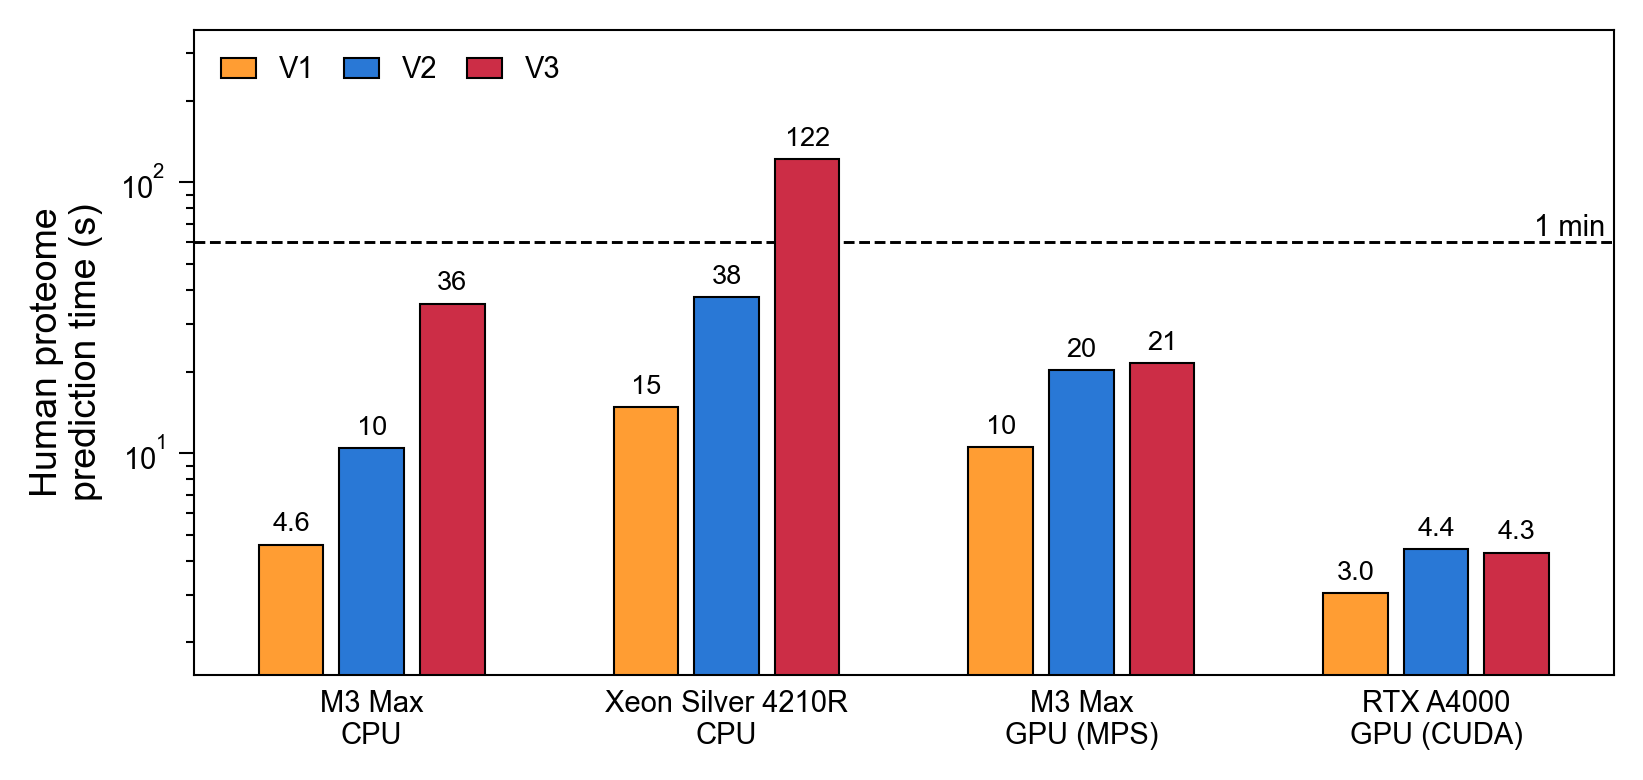

In [3]:
# bars start at the bottom of the log axis, not at 0 (see grouped_version_bars)
y_floor = min(seconds.values()) * 0.5
fig, ax = plt.subplots(figsize=(5.6, 2.7), dpi=150)
grouped_version_bars(ax, groups, seconds, group_gap=1.4, bottom=y_floor,
                     label_fmt=lambda v: f'{v:.0f}' if v >= 10 else f'{v:.1f}')
ax.set_yscale('log')
ax.set_ylim(y_floor, max(max(seconds.values()) * 3, ONE_MINUTE_S * 2))
ax.axhline(ONE_MINUTE_S, color='black', linewidth=0.7, linestyle='--', zorder=2)
ax.text(ax.get_xlim()[1], ONE_MINUTE_S, '1 min ', ha='right', va='bottom', fontsize=7)
ax.set_ylabel('Human proteome\nprediction time (s)', fontsize=9)
version_legend(ax, loc='upper left', ncol=3)
plt.tight_layout()
save_panel(fig, 'figure_1E')